# Part 2 - Diffusion Fine-Tuning (Pokemon BLIP captions, Stable Diffusion 1.5)

**Author: Sneha Singh** (Part 2). Teammate: Ritika Neema. Team: Pair_Programming_Team_05.
Executed on Google Colab (NVIDIA L4); outputs below are from that run.
Two LoRA runs (rank 4 vs rank 16, same data and steps) compared with the base model.
Set `SMOKE = True` for a tiny local pass; `False` for the real run on a CUDA GPU.

In [2]:
# Cell 0 - Colab setup (skipped locally). Pins match the versions tested locally.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers==0.42.0", "peft==0.21.2", "accelerate==1.12.0",
                    "datasets==5.1.0", "torchmetrics==1.9.0", "torch-fidelity==0.4.0", "lpips==0.1.4", "transformers==5.2.0",
                    "safetensors", "pandas", "matplotlib"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"])   # Colab torchao is too old for peft; unused here
    from google.colab import drive
    drive.mount("/content/drive")          # outputs live on Drive so a disconnect loses nothing

# Cell 1 - run information (required)
import subprocess, sys, os, random, platform, numpy as np, torch
SEED = 266
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
def _git_commit():
    here = os.path.abspath(os.getcwd())
    for _ in range(6):
        if os.path.isdir(os.path.join(here, ".git")):
            hit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=here, capture_output=True, text=True).stdout.strip()
            if hit:
                return hit
        parent = os.path.dirname(here)
        if parent == here:
            break
        here = parent
    return subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
commit = _git_commit()
import diffusers, transformers, peft, datasets
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else ("Apple MPS" if torch.backends.mps.is_available() else "CPU")
print({"commit": commit or "n/a", "python": sys.version.split()[0], "torch": torch.__version__,
       "diffusers": diffusers.__version__, "transformers": transformers.__version__, "peft": peft.__version__,
       "datasets": datasets.__version__, "gpu": gpu, "seed": SEED})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


{'commit': 'n/a', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'diffusers': '0.42.0', 'transformers': '5.2.0', 'peft': '0.21.2', 'datasets': '5.1.0', 'gpu': 'NVIDIA L4', 'seed': 266}


In [3]:
# Cell 2 - configuration
SMOKE = not torch.cuda.is_available()   # auto: tiny check without CUDA, full run on a CUDA GPU (override here if needed)
MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET = "reach-vb/pokemon-blip-captions"
LOCAL_DATA = "Part2/data/pokemon-blip-captions"
HF_USER = "YOUR_HF_USERNAME"       # TODO set before pushing
PUSH = False                       # True once logged in (huggingface_hub.login / HF_TOKEN)

DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
DTYPE = torch.float16 if DEV == "cuda" else torch.float32   # frozen base dtype; LoRA params stay fp32
if SMOKE:
    N_IMG, RES, STEPS, MICRO_BS, ACCUM, GEN_STEPS, PROMPT_IDX, N_PAIRS, CKPT_EVERY = 32, 256, 5, 1, 1, 10, [0, 10, 15], 3, 100
else:
    N_IMG, RES, STEPS, MICRO_BS, ACCUM, GEN_STEPS, PROMPT_IDX, N_PAIRS, CKPT_EVERY = None, 512, 1500, 2, 2, 30, list(range(20)), 25, 100
BS = MICRO_BS * ACCUM        # effective batch size (micro-batch x gradient accumulation); lower MICRO_BS if CUDA OOM
LR, GUIDANCE = 1e-4, 7.5
RUNS = [{"name": "lora_r4", "rank": 4}, {"name": "lora_r16", "rank": 16}]   # same data + steps
if IN_COLAB and not SMOKE:
    OUT = "/content/drive/MyDrive/data266_lab2_p2"; EVAL = f"{OUT}/eval"     # persists across disconnects
else:
    OUT, EVAL = ("outputs/p2_smoke" if SMOKE else "outputs/p2"), ("outputs/p2_smoke/eval" if SMOKE else "eval")   # smoke never mixes with real runs
os.makedirs(OUT, exist_ok=True); os.makedirs(EVAL, exist_ok=True)
print({"SMOKE": SMOKE, "device": DEV, "res": RES, "steps": STEPS, "batch": BS})

{'SMOKE': False, 'device': 'cuda', 'res': 512, 'steps': 1500, 'batch': 4}


## 2.1 Data preparation
Pokemon BLIP captions (`reach-vb/pokemon-blip-captions`, 833 image-caption pairs). Corrupt and duplicate
images are removed, then a 90/10 split with seed 266. Test images are used only for evaluation.

In [4]:
# Load: local copy if present (no download), else Hugging Face
import hashlib
from datasets import load_from_disk, load_dataset
if os.path.isdir(LOCAL_DATA):
    ds = load_from_disk(LOCAL_DATA)
else:
    ds = load_dataset(DATASET, split="train"); os.makedirs(os.path.dirname(LOCAL_DATA), exist_ok=True); ds.save_to_disk(LOCAL_DATA)
n_raw = len(ds)
if N_IMG: ds = ds.select(range(N_IMG))
seen, keep, corrupt, dup = set(), [], 0, 0
for i in range(len(ds)):
    ex = ds[i]
    try:
        im = ex["image"].convert("RGB"); im.load()
    except Exception:
        corrupt += 1; continue
    h = hashlib.md5(im.resize((32, 32)).tobytes()).hexdigest()
    if h in seen: dup += 1; continue
    seen.add(h); keep.append(i)
print({"raw": n_raw, "used": len(ds), "corrupt_removed": corrupt, "duplicates_removed": dup, "kept": len(keep)})

{'raw': 833, 'used': 833, 'corrupt_removed': 0, 'duplicates_removed': 0, 'kept': 833}


In [5]:
# 90/10 split (seed 266), resize + center crop to model resolution
from torchvision import transforms
rng = random.Random(SEED); order = keep[:]; rng.shuffle(order)
n_test = max(1, round(0.1 * len(order)))
test_idx, train_idx = order[:n_test], order[n_test:]
tf = transforms.Compose([transforms.Resize(RES), transforms.CenterCrop(RES)])
get = lambda i: (tf(ds[i]["image"].convert("RGB")), ds[i]["text"])
train = [get(i) for i in train_idx]; test = [get(i) for i in test_idx]
print({"train": len(train), "test": len(test), "res": RES})

{'train': 750, 'test': 83, 'res': 512}


**Dataset description.** Pokemon official-artwork images with BLIP-generated captions (one caption each).
Limitations / biases: (1) captions are machine-generated and short, so they miss attributes and sometimes
mislabel colour or species; (2) the images are copyrighted characters in one clean-artwork style with
mostly single centred subjects, so the model learns that style and is weak on scenes and multiple characters.
License: characters are copyrighted, so the resulting model is for non-commercial research only (see report C4).

## 2.3 Prompts (written before training)
20 fixed prompts: 10 in-domain (test-set captions), 5 out-of-domain, 5 compositional.
The file `eval/p2_prompts.json` was written before the training cell. If that file is already there, the cell loads it and does not write a new set.


In [6]:
import json, os
from collections import Counter
# Committed eval/p2_prompts.json is the fixed set. The Drive copy is only a fallback.
prompt_path = next((p for p in ("eval/p2_prompts.json", f"{EVAL}/p2_prompts.json") if os.path.exists(p)), None)
if prompt_path:
    PROMPTS = json.load(open(prompt_path))
else:
    in_domain = [c for _, c in test[:10]] if len(test) >= 10 else [c for _, c in test] + [c for _, c in train[:10 - len(test)]]
    out_of_domain = ["a photograph of a mountain lake at sunrise", "a red sports car on a city street",
                     "a bowl of fruit on a wooden table", "an astronaut riding a horse on the moon",
                     "a cozy living room with a fireplace"]
    compositional = ["two pokemon, one red and one blue, standing side by side", "a yellow pokemon holding a green leaf",
                     "three small round pokemon in a row, the left one purple", "a blue pokemon on top of a red box",
                     "a pink pokemon next to a black pokemon, white background"]
    PROMPTS = [{"id": i, "type": t, "prompt": p} for i, (t, p) in enumerate(
        [("in-domain", p) for p in in_domain] + [("out-of-domain", p) for p in out_of_domain] + [("compositional", p) for p in compositional])]
    if not SMOKE:
        os.makedirs("eval", exist_ok=True)
        json.dump(PROMPTS, open("eval/p2_prompts.json", "w"), indent=1)
        os.makedirs(EVAL, exist_ok=True)
        json.dump(PROMPTS, open(f"{EVAL}/p2_prompts.json", "w"), indent=1)
counts = Counter(p["type"] for p in PROMPTS)
assert [counts[t] for t in ("in-domain", "out-of-domain", "compositional")] == [10, 5, 5], counts
test_caps = [cap for _, cap in test]
missing = [p["prompt"] for p in PROMPTS if p["type"] == "in-domain" and p["prompt"] not in test_caps]
assert not missing, missing
sel = [PROMPTS[i] for i in PROMPT_IDX]
print(len(PROMPTS), "prompts;", len(sel), "used this run")
print(dict(counts), "in-domain captions are in the test split")


20 prompts; 20 used this run


In [7]:
from google.colab import files
files.download(f"{EVAL}/p2_prompts.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2.2 Fine-tuning
Two LoRA runs on the UNet attention projections (`to_q, to_k, to_v, to_out.0`): rank 4 and rank 16,
`lora_alpha = rank`, same data, steps, batch size and learning rate. Base weights frozen.
Design notes from the papers: LoRA (Hu 2021) adapts only attention projections and finds small ranks already
match larger ones, so we expect r=4 and r=16 to be close and test that. Rombach 2022: the UNet denoises latents
of a frozen VAE and text conditions via cross-attention, so only the UNet is trained (VAE and text encoder frozen).

In [8]:
import time, gc
from diffusers import StableDiffusionPipeline, DDPMScheduler
from peft import LoraConfig
from diffusers.utils import convert_state_dict_to_diffusers
from peft.utils import get_peft_model_state_dict
from peft import set_peft_model_state_dict

def mem_peak():
    if DEV == "cuda": return torch.cuda.max_memory_allocated() / 2**30
    if DEV == "mps": return torch.mps.driver_allocated_memory() / 2**30   # current, not strictly peak
    return float("nan")

def train_lora(name, rank):
    out_dir = f"{OUT}/{name}"; ckpt_path = f"{out_dir}/ckpt.pt"; row_path = f"{out_dir}/train_row.json"
    if os.path.exists(row_path):                      # finished earlier (e.g. before a disconnect): reuse
        print(name, "already trained; skipping"); return json.load(open(row_path))
    os.makedirs(out_dir, exist_ok=True)
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if DEV == "cuda": torch.cuda.reset_peak_memory_stats()
    pipe = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=DTYPE, variant="fp16", safety_checker=None).to(DEV)
    vae, unet, te, tok = pipe.vae, pipe.unet, pipe.text_encoder, pipe.tokenizer
    sched = DDPMScheduler.from_config(pipe.scheduler.config)
    for m in (vae, unet, te): m.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params: p.data = p.data.float()
    n_params = sum(p.numel() for p in params)
    opt = torch.optim.AdamW(params, lr=LR)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEV == "cuda"))
    to_t = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
    g = torch.Generator().manual_seed(SEED)           # same data order for every run
    start, losses, elapsed = 0, [], 0.0
    if os.path.exists(ckpt_path):                     # resume after a disconnect
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        set_peft_model_state_dict(unet, ck["lora"]); opt.load_state_dict(ck["opt"]); g.set_state(ck["g"])
        start, losses, elapsed = ck["step"], ck["losses"], ck["elapsed"]; print(f"{name}: resumed at step {start}")
    unet.train(); t0 = time.time()
    for step in range(start, STEPS):
        for _ in range(ACCUM):
            idx = torch.randint(0, len(train), (MICRO_BS,), generator=g).tolist()
            x = torch.stack([to_t(train[i][0]) for i in idx]).to(DEV, DTYPE)
            ids = tok([train[i][1] for i in idx], padding="max_length", max_length=tok.model_max_length,
                      truncation=True, return_tensors="pt").input_ids.to(DEV)
            with torch.no_grad():
                lat = vae.encode(x).latent_dist.sample() * vae.config.scaling_factor
                emb = te(ids)[0]
            noise = torch.randn_like(lat)
            t = torch.randint(0, sched.config.num_train_timesteps, (MICRO_BS,), device=DEV)
            with torch.autocast(DEV, dtype=torch.float16, enabled=(DEV == "cuda")):
                pred = unet(sched.add_noise(lat, noise, t), t, emb).sample
            loss = torch.nn.functional.mse_loss(pred.float(), noise.float()) / ACCUM
            scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad()
        losses.append(loss.item() * ACCUM)
        done = step + 1 - start
        if done == 20 or (step + 1) % max(1, STEPS // 10) == 0:
            sec = elapsed + time.time() - t0
            print(f"{name} step {step+1}/{STEPS} loss {losses[-1]:.4f} | {sec/(step+1):.2f}s/step | ETA {(STEPS-step-1)*sec/(step+1)/60:.1f} min")
        if (step + 1) % CKPT_EVERY == 0 and step + 1 < STEPS:
            torch.save({"step": step + 1, "lora": get_peft_model_state_dict(unet), "opt": opt.state_dict(), "g": g.get_state(),
                        "losses": losses, "elapsed": elapsed + time.time() - t0}, ckpt_path)
    if DEV == "cuda": torch.cuda.synchronize()
    secs = elapsed + time.time() - t0
    StableDiffusionPipeline.save_lora_weights(out_dir, unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
    row = {"run": name, "rank": rank, "trainable_params": n_params, "lr": LR, "steps": STEPS, "batch": BS,
           "peak_mem_gb": round(mem_peak(), 2), "train_seconds": round(secs, 1), "gpu_hours": round(secs / 3600, 4),
           "final_loss": round(float(np.mean(losses[-max(1, STEPS // 10):])), 4)}
    json.dump(row, open(row_path, "w"));
    if os.path.exists(ckpt_path): os.remove(ckpt_path)
    del pipe, unet, vae, te, opt; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()
    return row

train_rows = [train_lora(r["name"], r["rank"]) for r in RUNS]
import pandas as pd
train_df = pd.DataFrame(train_rows); display(train_df)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or audit

lora_r4 step 20/1500 loss 0.0528 | 0.71s/step | ETA 17.6 min
lora_r4 step 150/1500 loss 0.0075 | 0.58s/step | ETA 13.0 min
lora_r4 step 300/1500 loss 0.1199 | 0.58s/step | ETA 11.6 min
lora_r4 step 450/1500 loss 0.1055 | 0.58s/step | ETA 10.1 min
lora_r4 step 600/1500 loss 0.0316 | 0.58s/step | ETA 8.6 min
lora_r4 step 750/1500 loss 0.0954 | 0.58s/step | ETA 7.2 min
lora_r4 step 900/1500 loss 0.1956 | 0.58s/step | ETA 5.8 min
lora_r4 step 1050/1500 loss 0.0514 | 0.58s/step | ETA 4.3 min
lora_r4 step 1200/1500 loss 0.1551 | 0.58s/step | ETA 2.9 min
lora_r4 step 1350/1500 loss 0.0279 | 0.58s/step | ETA 1.4 min
lora_r4 step 1500/1500 loss 0.0274 | 0.58s/step | ETA 0.0 min


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or audit

lora_r16 step 20/1500 loss 0.0528 | 0.58s/step | ETA 14.2 min
lora_r16 step 150/1500 loss 0.0075 | 0.58s/step | ETA 13.0 min
lora_r16 step 300/1500 loss 0.1195 | 0.58s/step | ETA 11.5 min
lora_r16 step 450/1500 loss 0.1055 | 0.58s/step | ETA 10.1 min
lora_r16 step 600/1500 loss 0.0315 | 0.58s/step | ETA 8.6 min
lora_r16 step 750/1500 loss 0.0951 | 0.58s/step | ETA 7.2 min
lora_r16 step 900/1500 loss 0.1950 | 0.58s/step | ETA 5.8 min
lora_r16 step 1050/1500 loss 0.0509 | 0.58s/step | ETA 4.3 min
lora_r16 step 1200/1500 loss 0.1550 | 0.58s/step | ETA 2.9 min
lora_r16 step 1350/1500 loss 0.0276 | 0.58s/step | ETA 1.4 min
lora_r16 step 1500/1500 loss 0.0275 | 0.58s/step | ETA 0.0 min


,run,rank,trainable_params,lr,steps,batch,peak_mem_gb,train_seconds,gpu_hours,final_loss
0,lora_r4,4,797184,0.0001,1500,4,4.22,864.2,0.2401,0.0535
1,lora_r16,16,3188736,0.0001,1500,4,4.27,863.8,0.2399,0.0533


In [9]:
# Push both adapters + model card to Hugging Face (set HF_USER, PUSH=True)
CARD = '''---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
tags: [text-to-image, lora, diffusers]
---
# {name}
LoRA (rank {rank}) on SD 1.5 UNet attention, trained on reach-vb/pokemon-blip-captions
({n} train images, {steps} steps, batch {bs}, lr {lr}, seed 266). Non-commercial research only:
the dataset shows copyrighted characters. Known limits: weak on out-of-domain and multi-character prompts;
may reproduce training images (see memorization check in the report).
'''
for r in train_rows:
    open(f"{OUT}/{r['run']}/README.md", "w").write(CARD.format(name=r["run"], rank=r["rank"], n=len(train), steps=STEPS, bs=BS, lr=LR))
if PUSH:
    from huggingface_hub import HfApi
    api = HfApi()
    for r in train_rows:
        rid = f"{HF_USER}/data266-lab2-p2-{r['run']}"
        api.create_repo(rid, exist_ok=True, private=False); api.upload_folder(folder_path=f"{OUT}/{r['run']}", repo_id=rid)
        print("pushed", rid)

## 2.3 Image generation
Base model and both runs, seeds 0 and 1, same sampler settings (40 images per model in the full run).

In [10]:
def make_pipe():
    p = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=DTYPE, variant="fp16", safety_checker=None).to(DEV)
    p.set_progress_bar_config(disable=True); return p

from PIL import Image
os.makedirs(f"{OUT}/images", exist_ok=True)
images = {}   # (model, prompt_id, seed) -> PIL
for model in ["base"] + [r["name"] for r in RUNS]:
    pipe = make_pipe()
    if model != "base": pipe.load_lora_weights(f"{OUT}/{model}")
    for p in sel:
        for s in (0, 1):
            f = f"{OUT}/images/{model}_p{p['id']}_s{s}.png"
            if os.path.exists(f): images[(model, p["id"], s)] = Image.open(f).convert("RGB"); continue   # resume
            gen = torch.Generator("cpu").manual_seed(s)
            images[(model, p["id"], s)] = pipe(p["prompt"], num_inference_steps=GEN_STEPS, guidance_scale=GUIDANCE,
                                               height=RES, width=RES, generator=gen).images[0]
            images[(model, p["id"], s)].save(f)
    del pipe; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()
    print(model, "done")
print(len(images), "images")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or audit

base done


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

... (3 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or audit

lora_r16 done
120 images


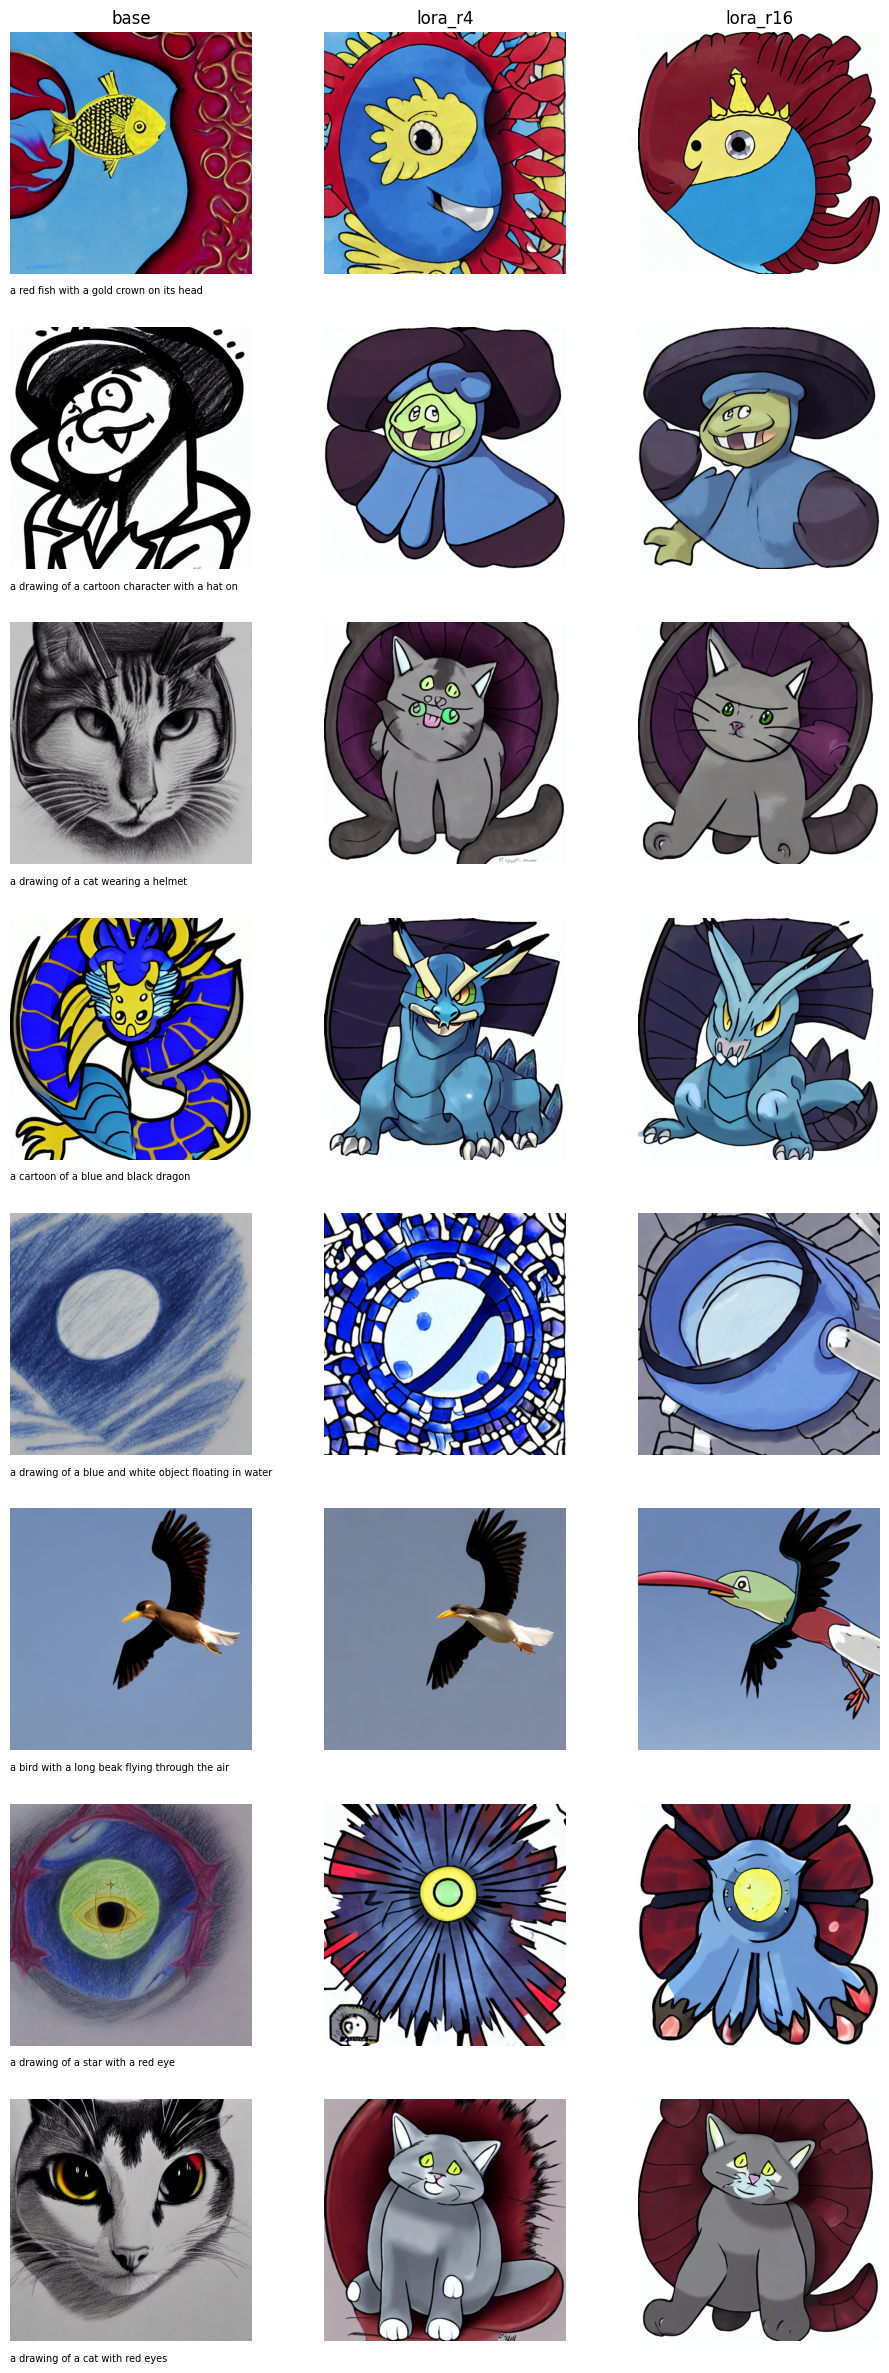

In [11]:
# Side-by-side grids: base | run 1 | run 2 (seed 0), up to 8 prompts
import matplotlib.pyplot as plt
models = ["base"] + [r["name"] for r in RUNS]
show = sel[:8]
fig, ax = plt.subplots(len(show), 3, figsize=(9, 3 * len(show)), squeeze=False)
for r, p in enumerate(show):
    for c, m in enumerate(models):
        ax[r][c].imshow(images[(m, p["id"], 0)]); ax[r][c].axis("off")
        if r == 0: ax[r][c].set_title(m)
    ax[r][0].text(0, -0.05, p["prompt"][:60], transform=ax[r][0].transAxes, fontsize=7, va="top")
plt.tight_layout(); plt.savefig(f"{OUT}/grid.png", dpi=110); plt.show()

## 2.4 Evaluation
Primary: KID (in-domain generations vs test images, lower is better, noisy at small n) and CLIP score.
Secondary: diversity = mean LPIPS between the two seeds of each prompt. Efficiency: GPU-hours and peak memory (table above).

In [12]:
from transformers import CLIPModel, CLIPProcessor
import lpips
from torchmetrics.image.kid import KernelInceptionDistance
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEV).eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
lp = lpips.LPIPS(net="alex").to(DEV)
to_t = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
u8 = lambda ims: torch.stack([torch.from_numpy(np.array(i.resize((299, 299)))).permute(2, 0, 1) for i in ims])

def clip_score(m):
    sc = []
    for p in sel:
        for s in (0, 1):
            inp = cproc(text=[p["prompt"]], images=[images[(m, p["id"], s)]], return_tensors="pt", padding=True).to(DEV)
            with torch.no_grad(): o = clip(**inp)
            sc.append(float(o.logits_per_image / clip.logit_scale.exp()))
    return float(np.mean(sc))

def diversity(m):
    d = []
    for p in sel:
        a, b = (to_t(images[(m, p["id"], s)]).unsqueeze(0).to(DEV) for s in (0, 1))
        with torch.no_grad(): d.append(lp(a, b).item())
    return float(np.mean(d))

def kid(m):
    ids = [p["id"] for p in sel if p["type"] == "in-domain"]
    fake = [images[(m, i, s)] for i in ids for s in (0, 1)]; real = [im for im, _ in test]
    k = KernelInceptionDistance(subset_size=max(2, min(len(fake), len(real), 50)))
    k.update(u8(real), real=True); k.update(u8(fake), real=False)
    mu, sd = k.compute(); return float(mu), float(sd)

rows = []
for m in models:
    mu, sd = kid(m)
    rows.append({"model": m, "KID_mean": round(mu, 5), "KID_std": round(sd, 5), "CLIP": round(clip_score(m), 4), "LPIPS_diversity": round(diversity(m), 4)})
res = pd.DataFrame(rows)
eff = train_df.set_index("run")[["trainable_params", "gpu_hours", "peak_mem_gb"]]
res = res.merge(eff, left_on="model", right_index=True, how="left")
display(res); res.to_csv(f"{EVAL}/p2_results.csv", index=False)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

... (11 outputs left out)

100%|██████████| 233M/233M [00:01<00:00, 181MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:04<00:00, 19.5MB/s]
/tmp/ipykernel_8236/3570182964.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  sc.append(float(o.logits_per_image / clip.logit_scale.exp()))


,model,KID_mean,KID_std,CLIP,LPIPS_diversity,trainable_params,gpu_hours,peak_mem_gb
0,base,0.06024,0.00852,0.3220,0.7349,NaN,NaN,NaN
1,lora_r4,0.02671,0.00617,0.3110,0.7178,797184.0,0.2401,4.22
2,lora_r16,0.02314,0.00506,0.3155,0.7123,3188736.0,0.2399,4.27


### Human evaluation (blinded, 25 pairs)
Final run vs base, left/right randomized. 3+ raters (both members + one outside the team) fill `winner` with L or R. Answer key is a separate file.

In [13]:
FINAL = RUNS[-1]["name"]   # update after reviewing results; justify in report
pairs = [(p["id"], s) for p in PROMPTS for s in (0, 1)]
pairs = [(i, s) for i, s in pairs if ("base", i, s) in images]
r = random.Random(SEED); r.shuffle(pairs); pairs = pairs[:N_PAIRS]; pairs.sort()   # random 25 of the 40, seed 266
r = random.Random(SEED + 1); rows_k, rows_r = [], []
os.makedirs(f"{OUT}/human_eval", exist_ok=True)
for n, (pid, s) in enumerate(pairs):
    base_left = r.random() < 0.5
    L, R = (("base", FINAL) if base_left else (FINAL, "base"))
    images[(L, pid, s)].save(f"{OUT}/human_eval/pair{n:02d}_L.png"); images[(R, pid, s)].save(f"{OUT}/human_eval/pair{n:02d}_R.png")
    rows_r.append({"pair": n, "prompt": next(p["prompt"] for p in PROMPTS if p["id"] == pid), "rater1": "", "rater2": "", "rater3": ""})
    rows_k.append({"pair": n, "left": L, "right": R})
blank = pd.DataFrame(rows_r)
review_out = "eval/p2_human_review.csv" if os.path.exists("eval/p2_human_review.csv") else f"{EVAL}/p2_human_review.csv"
keep = False
if os.path.exists(review_out):
    old_review = pd.read_csv(review_out)
    filled = [c for c in old_review.columns if str(c).startswith("rater") and old_review[c].astype(str).str.strip().ne("").all()]
    keep = len(old_review) == len(blank) and old_review["prompt"].tolist() == blank["prompt"].tolist() and len(filled) >= 3
if keep:
    print(len(pairs), "pairs; kept existing ratings in", review_out)
else:
    os.makedirs(os.path.dirname(review_out) or ".", exist_ok=True)
    blank.to_csv(review_out, index=False)
    print(len(pairs), "pairs written")
key_df = pd.DataFrame(rows_k)
key_df.to_csv(f"{OUT}/human_eval/answer_key.csv", index=False)  # do not show raters
if os.path.isdir("Part2/sneha_singh/human_eval"):
    key_df.to_csv("Part2/sneha_singh/human_eval/answer_key.csv", index=False)

25 pairs written


In [14]:
# Human evaluation results: ratings were collected offline with a blinded page
# (Part2/sneha_singh/human_eval/rate_images.html), one CSV per rater, and are read here with the answer key.
import glob, math, json, os, pandas as pd
FINAL = globals().get("FINAL", "lora_r16")
HE = "Part2/sneha_singh/human_eval" if os.path.isdir("Part2/sneha_singh/human_eval") else f"{OUT}/human_eval"
first = lambda *ps: next(p for p in ps if os.path.exists(p))
key = pd.read_csv(f"{HE}/answer_key.csv").set_index("pair")
review = pd.read_csv(first("eval/p2_human_review.csv", f"{EVAL}/p2_human_review.csv")).set_index("pair")
ptype = {x["prompt"]: x["type"] for x in json.load(open(first("eval/p2_prompts.json", f"{EVAL}/p2_prompts.json")))}
rows = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{HE}/ratings/ratings_*.csv"))])
rows = rows[rows.choice.isin(["L", "R"])].copy()
rows["winner"] = [key.loc[q, "left" if c == "L" else "right"] for q, c in zip(rows.pair, rows.choice)]
rows["final_won"] = rows.winner == FINAL
rows["type"] = rows.pair.map(review.prompt).map(ptype)
n, w = len(rows), int(rows.final_won.sum()); p_, z = w / n, 1.96
ctr = (p_ + z * z / (2 * n)) / (1 + z * z / n); half = z * math.sqrt(p_ * (1 - p_) / n + z * z / (4 * n * n)) / (1 + z * z / n)
print({"raters": rows.rater.nunique(), "votes": n, "final": FINAL, "final_wins": w, "win_rate": round(p_, 3), "ci95": [round(ctr - half, 3), round(ctr + half, 3)]})
print("per rater:", rows.groupby("rater").final_won.mean().round(3).to_dict())
print("by prompt type (win rate, votes):", {k: (round(float(v["mean"]), 3), int(v["count"])) for k, v in rows.groupby("type").final_won.agg(["mean", "count"]).iterrows()})
pv = rows.pivot(index="pair", columns="rater", values="final_won")
print("pairs where all raters agree:", int((pv.nunique(axis=1) == 1).sum()), "of", len(pv))


{'raters': 3, 'votes': 75, 'final': 'lora_r16', 'final_wins': 29, 'win_rate': 0.387, 'ci95': [0.285, 0.5]}
per rater: {'Rajesh': 0.4, 'Ritika Neema': 0.44, 'Sneha Singh': 0.32}
by prompt type (win rate, votes): {'compositional': (0.278, 18), 'in-domain': (0.41, 39), 'out-of-domain': (0.444, 18)}
pairs where all raters agree: 16 of 25


### Safety (C4): NSFW filter and memorization check

In [15]:
# NSFW filter: SD safety checker run on every generated image
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor
sc = StableDiffusionSafetyChecker.from_pretrained(MODEL, subfolder="safety_checker", variant="fp16").to(DEV).eval()
fe = CLIPImageProcessor.from_pretrained(MODEL, subfolder="feature_extractor")
flagged = 0
for k, im in images.items():
    inp = fe(im, return_tensors="pt").to(DEV)
    with torch.no_grad():
        _, f = sc(images=[np.array(im)], clip_input=inp.pixel_values.to(sc.dtype))
    flagged += int(f[0])
print({"images_checked": len(images), "flagged_nsfw": flagged})
del sc; _ = gc.collect()

config.json:   0%|          | 0.00/4.72k [00:00<?, ?B/s]

safety_checker/model.fp16.safetensors: reconstructing file:   0%|          |  0.00B /  608MB            

safety_checker/model.fp16.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: stable-diffusion-v1-5/stable-diffusion-v1-5
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or see

{'images_checked': 120, 'flagged_nsfw': 10}


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: stable-diffusion-v1-5/stable-diffusion-v1-5
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or see

{'lora_r4': 4, 'lora_r16': 4, 'base': 2}
{'in-domain': 8, 'compositional': 2}


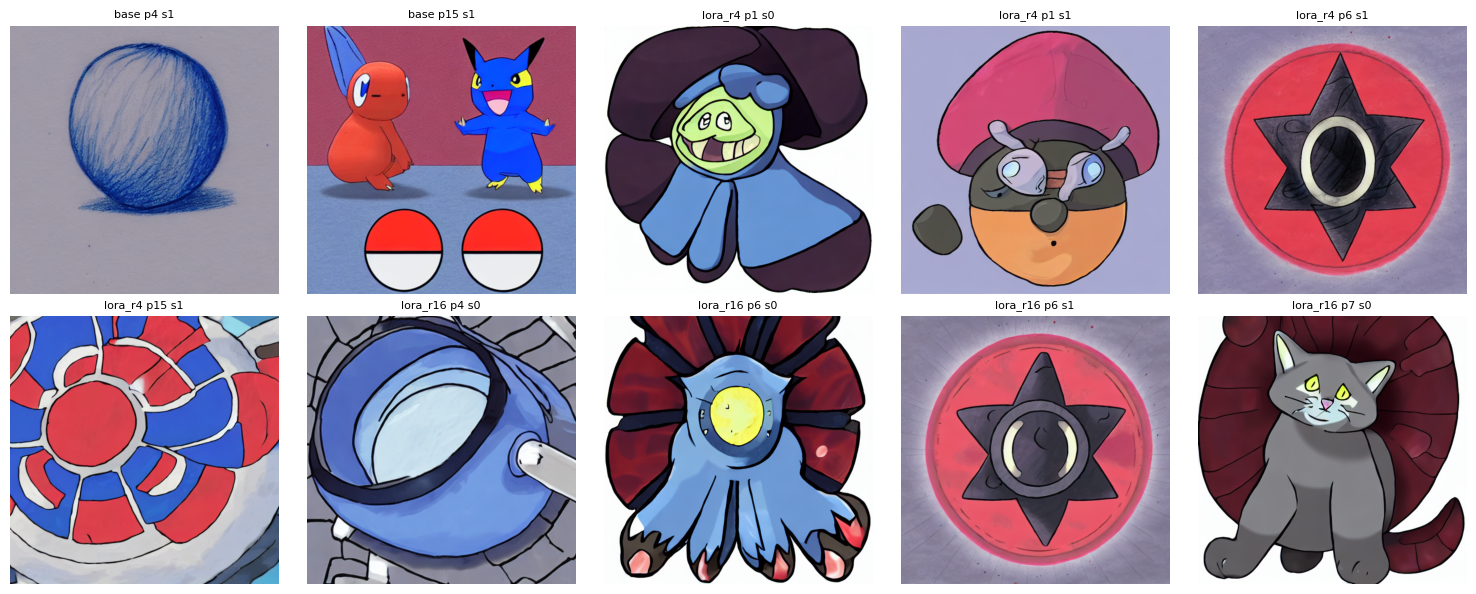

In [16]:
sc = StableDiffusionSafetyChecker.from_pretrained(MODEL, subfolder="safety_checker", variant="fp16").to(DEV).eval()
flag_list = []
for (m, pid, s), im in images.items():
    inp = fe(im, return_tensors="pt").to(DEV)
    with torch.no_grad():
        _, f = sc(images=[np.array(im)], clip_input=inp.pixel_values.to(sc.dtype))
    if f[0]: flag_list.append((m, pid, s))
del sc; _ = gc.collect()
print(pd.Series([m for m, _, _ in flag_list]).value_counts().to_dict())
print(pd.Series([next(p["type"] for p in PROMPTS if p["id"] == pid) for _, pid, _ in flag_list]).value_counts().to_dict())
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for a, (m, pid, s) in zip(ax.ravel(), flag_list[:10]):
    a.imshow(images[(m, pid, s)]); a.axis("off"); a.set_title(f"{m} p{pid} s{s}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/nsfw_flagged.png", dpi=100); plt.show()

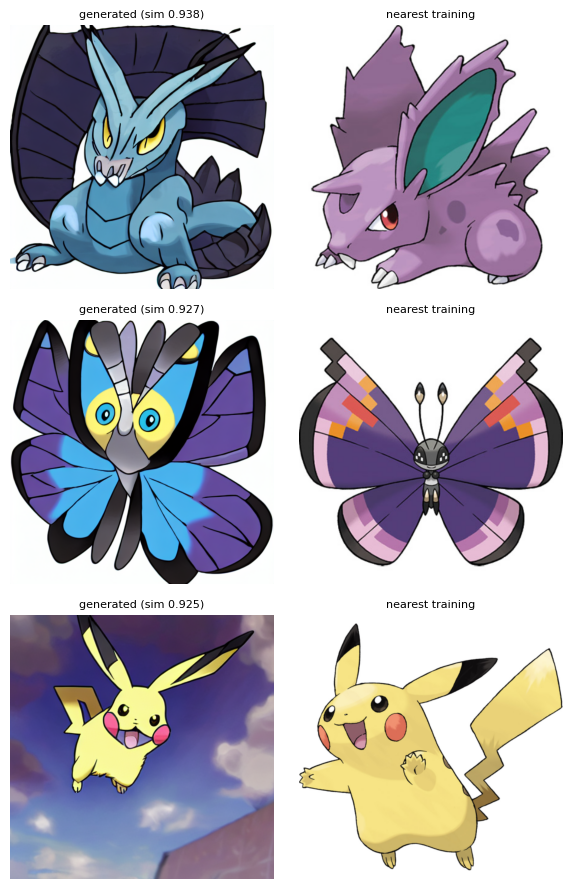

{'max_sim_per_prompt': [0.803, 0.876, 0.862, 0.938, 0.789, 0.813, 0.894, 0.866, 0.927, 0.925]}
{'max_tile_rms_to_nearest_train': [0.721, 0.647, 0.779, 0.639, 0.584, 0.718, 0.801, 0.798, 0.653, 0.714], 'note': 'RMS per tile (our normalization); values near/below ~0.15 would suggest a near-copy, higher means a new image'}


In [17]:
# Memorization: for 10 in-domain generations of the final run, nearest training image by CLIP cosine similarity; show 3 closest pairs
def cemb(ims, bs=32):
    out = []
    for i in range(0, len(ims), bs):
        inp = cproc(images=ims[i:i+bs], return_tensors="pt").to(DEV)
        with torch.no_grad(): e = clip.get_image_features(**inp)
        e = e if torch.is_tensor(e) else e.pooler_output
        out.append(torch.nn.functional.normalize(e, dim=-1).cpu())
    return torch.cat(out)
gen_ids = [p["id"] for p in sel if p["type"] == "in-domain"][:10]
gen_ims = [images[(FINAL, i, 0)] for i in gen_ids]
sim = cemb(gen_ims) @ cemb([im for im, _ in train]).T
best, arg = sim.max(dim=1)
top = best.argsort(descending=True)[:3].tolist()
fig, ax = plt.subplots(3, 2, figsize=(6, 9))
for r_, g in enumerate(top):
    ax[r_][0].imshow(gen_ims[g]); ax[r_][0].set_title(f"generated (sim {best[g]:.3f})", fontsize=8)
    ax[r_][1].imshow(train[arg[g]][0]); ax[r_][1].set_title("nearest training", fontsize=8)
    for a in ax[r_]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/memorization.png", dpi=110); plt.show()
print({"max_sim_per_prompt": [round(float(v), 3) for v in best]})

# Carlini et al. 2023 also use a stricter tile test: split into 16 non-overlapping tiles and take the MAX
# per-tile distance between the two images; small (they use 0.15 on normalized l2) means a near-exact copy.
def tile_dist(a, b, g=4):
    A, B = np.asarray(a.resize((RES, RES)), dtype=np.float32) / 255, np.asarray(b.resize((RES, RES)), dtype=np.float32) / 255
    t = RES // g
    return max(float(np.sqrt(np.mean((A[i*t:(i+1)*t, j*t:(j+1)*t] - B[i*t:(i+1)*t, j*t:(j+1)*t]) ** 2))) for i in range(g) for j in range(g))
td = [tile_dist(gen_ims[g], train[arg[g]][0]) for g in range(len(gen_ims))]
print({"max_tile_rms_to_nearest_train": [round(v, 3) for v in td],
       "note": "RMS per tile (our normalization); values near/below ~0.15 would suggest a near-copy, higher means a new image"})

In [18]:
# Push all generated images to a HF dataset with prompt, seed and model metadata
if PUSH:
    from datasets import Dataset, Features, Value, Image as HFImage
    recs = [{"image": im, "model": m, "prompt_id": pid, "prompt": next(p["prompt"] for p in PROMPTS if p["id"] == pid), "seed": s}
            for (m, pid, s), im in images.items()]
    Dataset.from_list(recs).cast_column("image", HFImage()).push_to_hub(f"{HF_USER}/data266-lab2-p2-images")

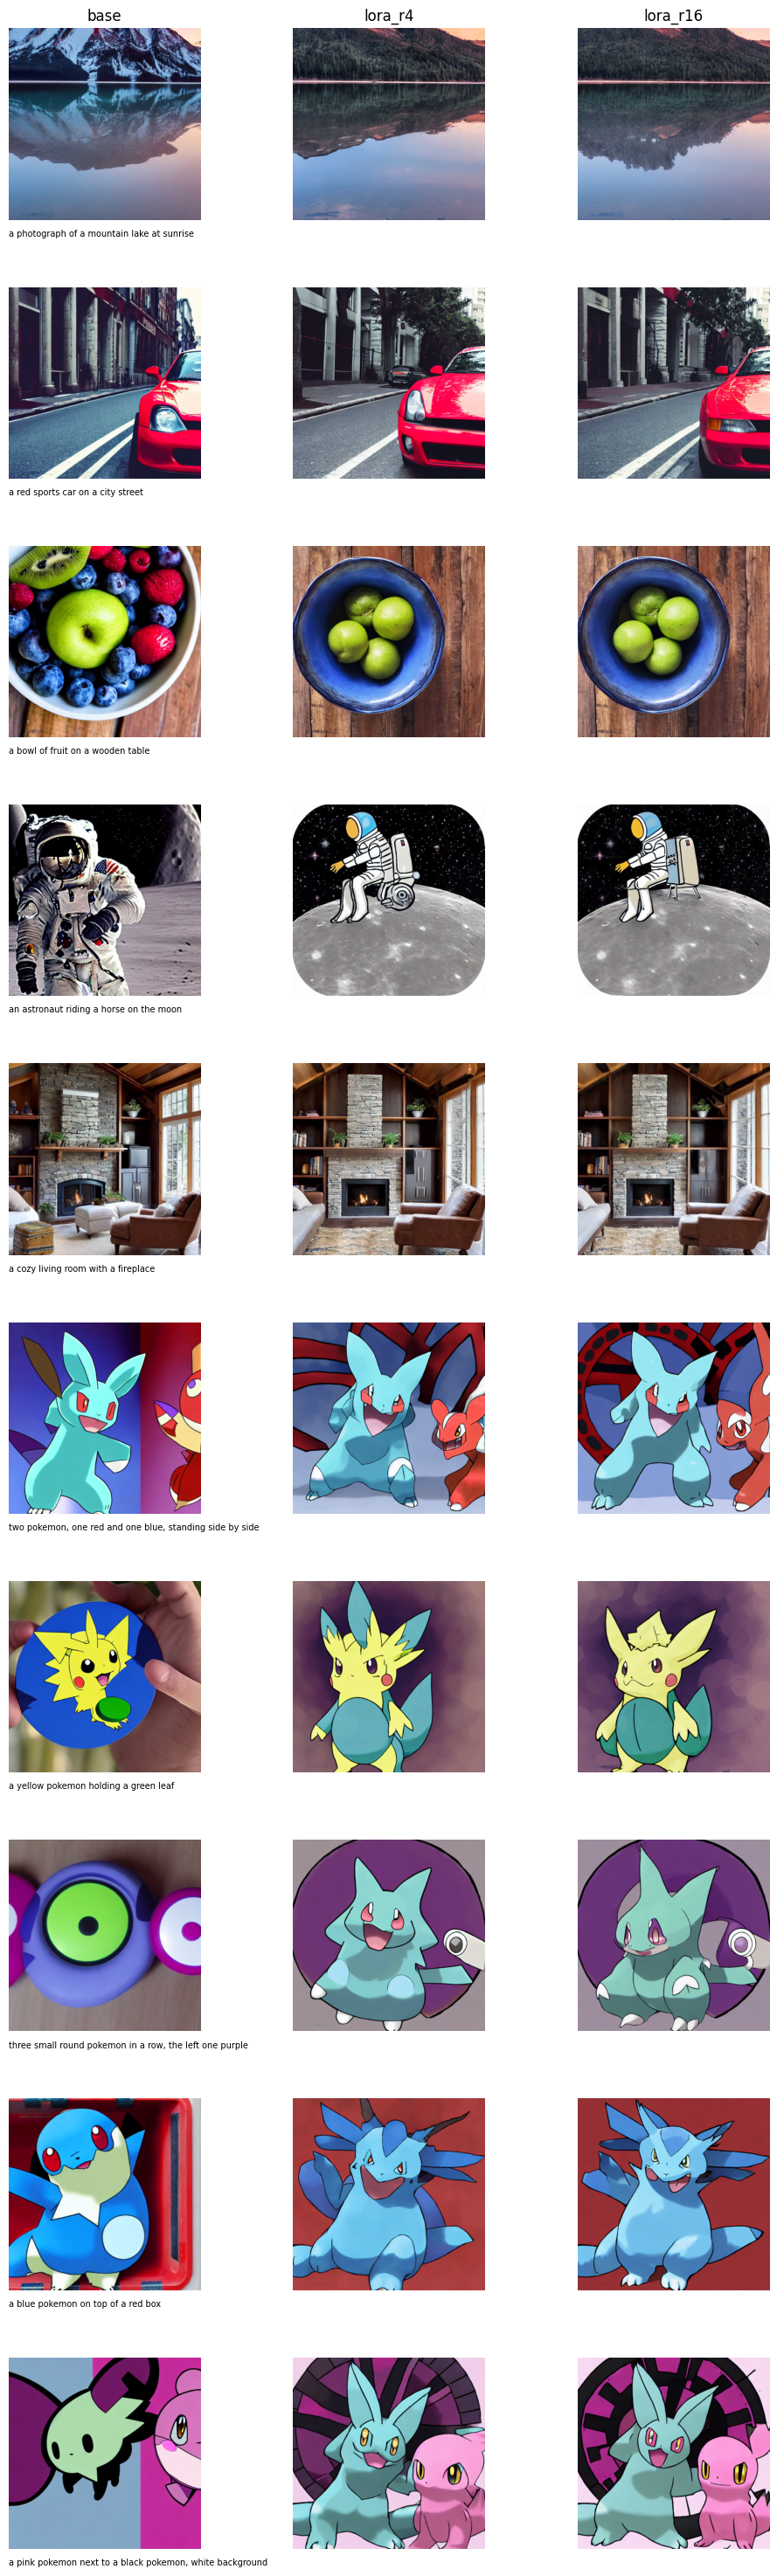

In [19]:
# Failure-mode candidates: out-of-domain and compositional prompts, base vs both runs (seed 0)
cand = [p for p in sel if p["type"] != "in-domain"]
if cand:
    fig, ax = plt.subplots(len(cand), 3, figsize=(9, 3 * len(cand)), squeeze=False)
    for r_, p in enumerate(cand):
        for c, m in enumerate(models):
            ax[r_][c].imshow(images[(m, p["id"], 0)]); ax[r_][c].axis("off")
            if r_ == 0: ax[r_][c].set_title(m)
        ax[r_][0].text(0, -0.05, p["prompt"][:60], transform=ax[r_][0].transAxes, fontsize=7, va="top")
    plt.tight_layout(); plt.savefig(f"{OUT}/failure_candidates.png", dpi=100); plt.show()

In [20]:
# Package everything and (on Colab) download it. Also pushed to Drive already.
import shutil
total_h = sum(r["gpu_hours"] for r in train_rows)
print({"training_gpu_hours_total": round(total_h, 3), "outputs": OUT, "eval": EVAL})
if not SMOKE:
    shutil.make_archive("/content/p2_outputs" if IN_COLAB else "p2_outputs", "zip", OUT)
    if IN_COLAB:
        from google.colab import files; files.download("/content/p2_outputs.zip")

{'training_gpu_hours_total': 0.48, 'outputs': '/content/drive/MyDrive/data266_lab2_p2', 'eval': '/content/drive/MyDrive/data266_lab2_p2/eval'}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# Hugging Face push: both adapters + model cards
HF_USER = "Sneha-subbu"
import os, re, json, pandas as pd
from google.colab import drive; drive.mount("/content/drive")
from huggingface_hub import login, HfApi
login()          # a box appears: paste your WRITE token there (not into chat)
api = HfApi()
OUT = "/content/drive/MyDrive/data266_lab2_p2"
res = pd.read_csv(f"{OUT}/eval/p2_results.csv")
rows = {r: json.load(open(f"{OUT}/{r}/train_row.json")) for r in ["lora_r4", "lora_r16"]}
FENCE = "`" * 3
HUMAN = ("Blinded human evaluation (25 pairs, 3 raters, 75 votes): rank 16 won 29/75 "
         "(win rate 0.387, 95% CI 0.285 to 0.5). "
         "Per rater: Rajesh 0.4, Ritika Neema 0.44, Sneha Singh 0.32. "
         "By prompt type: in-domain 0.41 (39 votes), out-of-domain 0.444 (18), compositional 0.278 (18).")

def card(run):
    t = rows[run]; r = res.set_index("model"); b, m = r.loc["base"], r.loc[run]
    final = " (selected final model)" if run == "lora_r16" else ""
    usage = (FENCE + "python\n"
             "import torch\n"
             "from diffusers import StableDiffusionPipeline\n"
             "pipe = StableDiffusionPipeline.from_pretrained('stable-diffusion-v1-5/stable-diffusion-v1-5', torch_dtype=torch.float16).to('cuda')\n"
             f"pipe.load_lora_weights('{HF_USER}/data266-lab2-p2-{run}')\n" + FENCE)
    return f"""---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
library_name: diffusers
tags: [text-to-image, lora, stable-diffusion, diffusers]
datasets: [reach-vb/pokemon-blip-captions]
---
# {run}{final}

LoRA adapter (rank {t['rank']}) for Stable Diffusion 1.5, fine-tuned on Pokemon BLIP captions.
DATA 266 Lab 2, Part 2 - Team 05 (Sneha Singh, Ritika Neema).

## Intended use and limits
Non-commercial research and coursework only. The training images show copyrighted characters; do not use commercially.

## Training
750 train / 83 test images (seed 266), 512px, {t['steps']} steps, batch {t['batch']}, lr {t['lr']},
{t['trainable_params']:,} trainable parameters, peak GPU memory {t['peak_mem_gb']} GB, {t['gpu_hours']} GPU-hours (NVIDIA L4).

## Evaluation (20 fixed prompts, seeds 0 and 1, 512px, 30 steps, guidance 7.5)
| model | KID (lower is better) | CLIP score | LPIPS diversity |
|---|---|---|---|
| base | {b.KID_mean:.5f} +/- {b.KID_std:.5f} | {b.CLIP:.4f} | {b.LPIPS_diversity:.4f} |
| {run} | {m.KID_mean:.5f} +/- {m.KID_std:.5f} | {m.CLIP:.4f} | {m.LPIPS_diversity:.4f} |

{HUMAN}

## Known failure modes
Compositional prompts often lose objects, attributes or counts; the same creature look repeats across unrelated prompts;
out-of-domain prompts drift toward the cartoon style. A CLIP plus tile-distance check on 10 generations found no near-copies of training images.

## Usage
{usage}
"""

for run in ["lora_r4", "lora_r16"]:
    open(f"{OUT}/{run}/README.md", "w").write(card(run))
    rid = f"{HF_USER}/data266-lab2-p2-{run}"
    api.create_repo(rid, exist_ok=True, private=False)
    api.upload_folder(folder_path=f"{OUT}/{run}", repo_id=rid, allow_patterns=["README.md", "pytorch_lora_weights.safetensors"])
    print("https://huggingface.co/" + rid)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


https://huggingface.co/Sneha-subbu/data266-lab2-p2-lora_r4
https://huggingface.co/Sneha-subbu/data266-lab2-p2-lora_r16


In [23]:
# Hugging Face: generated-image dataset (prompt, seed, model in metadata)
import os, re, json
from datasets import Dataset, Image as HFImage
OUT = "/content/drive/MyDrive/data266_lab2_p2"
HF_USER = "Sneha-subbu"
pm = {p["id"]: p for p in json.load(open(f"{OUT}/eval/p2_prompts.json"))}
recs = []
for f in sorted(os.listdir(f"{OUT}/images")):
    m = re.match(r"(.+)_p(\d+)_s(\d)\.png$", f)
    model, pid, seed = m.group(1), int(m.group(2)), int(m.group(3))
    recs.append({"image": f"{OUT}/images/{f}", "model": model, "prompt_id": pid,
                 "prompt": pm[pid]["prompt"], "prompt_type": pm[pid]["type"], "seed": seed})
print(len(recs), "images")
ds = Dataset.from_list(recs).cast_column("image", HFImage())
ds.push_to_hub(f"{HF_USER}/data266-lab2-p2-images")
print("https://huggingface.co/datasets/" + f"{HF_USER}/data266-lab2-p2-images")

120 images


Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp_1r12x6b.parquet    :   1%|1         |  524kB / 43.3MB            

Validating                    :           |   0%            

https://huggingface.co/datasets/Sneha-subbu/data266-lab2-p2-images


In [24]:
from huggingface_hub import HfApi
card = """---
license: creativeml-openrail-m
task_categories: [text-to-image]
---
# DATA 266 Lab 2 Part 2: generated images

120 images (3 models x 20 fixed prompts x seeds 0 and 1), 512px, 30 steps, guidance 7.5.
Columns: image, model (base / lora_r4 / lora_r16), prompt_id, prompt, prompt_type (in-domain / out-of-domain / compositional), seed.
Models: Stable Diffusion 1.5 and two LoRA adapters trained on reach-vb/pokemon-blip-captions.
Generated for coursework (Team 05: Sneha Singh, Ritika Neema). The training data shows copyrighted characters; non-commercial research use only.
"""
open("/content/dataset_card.md", "w").write(card)
HfApi().upload_file(path_or_fileobj="/content/dataset_card.md", path_in_repo="README.md",
                    repo_id="Sneha-subbu/data266-lab2-p2-images", repo_type="dataset")
print("done")

done


## Failure modes and final model choice

**Results summary** (20 fixed prompts, seeds 0 and 1, 512px; KID uses the 10 in-domain prompts, 20 images vs 83 test images, so it is noisy)

| model | KID (lower better) | CLIP score | LPIPS diversity | trainable params | GPU-hours | peak memory |
|---|---|---|---|---|---|---|
| base | 0.06024 +/- 0.00852 | 0.3220 | 0.7349 | - | - | - |
| lora_r4 | 0.02671 +/- 0.00617 | 0.3110 | 0.7178 | 797,184 | 0.2401 | 4.22 GB |
| lora_r16 | **0.02314 +/- 0.00506** | 0.3155 | 0.7123 | 3,188,736 | 0.2399 | 4.27 GB |

**Human evaluation** (blinded, 25 pairs of lora_r16 vs base, 3 raters, 75 votes; ratings were collected offline with `Part2/sneha_singh/human_eval/rate_images.html` and the numbers below are computed in the "Human evaluation results" cell above): rank 16 won **29/75** votes, win rate **0.387**, 95% CI **0.285 to 0.5**. Per rater: Rajesh 0.4, Ritika Neema 0.44, Sneha Singh 0.32. By prompt type: in-domain 0.41 (39 votes), out-of-domain 0.444 (18), compositional 0.278 (18). The raters agreed on 16 of 25 pairs. The interval includes 0.5, so the votes do not separate the two models.

**Failure mode 1 - compositional prompts lose requested content.** In `failure_candidates.png`, most compositional prompts drop something that was asked for: "a yellow pokemon holding a green leaf" shows no leaf; "three small round pokemon in a row, the left one purple" gives a single creature with the wrong count and no purple; "a blue pokemon on top of a red box" has a red background but no box; "a pink pokemon next to a black pokemon, white background" has no black creature and a patterned background. The base model drew the red box. This matches the lowest human win rate (0.278) on compositional pairs and the lower CLIP score of both LoRA runs (0.3110 and 0.3155 vs 0.3220): the model learned the dataset's single-centred-character look at the cost of counts, relations and attributes.

**Failure mode 2 - repeated outputs and style drift.** The same teal, pointy-eared creature appears across several unrelated prompts, and LPIPS diversity falls from 0.7349 (base) to 0.7178 and 0.7123. On out-of-domain prompts the photographic cases (mountain lake, red car, living room) stay realistic, but the fruit bowl turns into a few green fruits in a blue bowl and the astronaut becomes a cartoon figure with no horse (the base also did not draw a horse).

**Safety checks.** NSFW filter (SD safety checker) flagged 10 of 120 images (base 2, lora_r4 4, lora_r16 4; in-domain 8, compositional 2). All 10 were reviewed and are cartoon creatures, so they were kept. Memorization check (10 in-domain generations of lora_r16, seed 0): nearest-training CLIP similarity 0.789 to 0.938. The largest per-tile RMS on those pairs is 0.584 to 0.801, above the near-copy range Carlini et al. 2023 mark at about 0.15 on their own scaling. Limits: 10 prompts and one seed only. License: the training images show copyrighted characters, so both models are for non-commercial research.

**Final model: lora_r16.** It has the best KID (0.02314 vs 0.02671 for rank 4 and 0.06024 for base) and the best CLIP score of the two LoRA runs (0.3155 vs 0.3110). Training took 863.8 s (0.2399 GPU-hours, 4.27 GB) against 864.2 s (0.2401 GPU-hours, 4.22 GB) for rank 4. Rank 16 has 3,188,736 trainable parameters and rank 4 has 797,184. Rank 4 and rank 16 are close, within the KID noise, as the LoRA paper suggests for small ranks, so this choice is a small margin, not a large one. If the goal is following arbitrary or compositional prompts, the base model is preferable; for Pokemon-style generation, lora_r16 is the better model. Hugging Face: https://huggingface.co/Sneha-subbu/data266-lab2-p2-lora_r16, rank 4: https://huggingface.co/Sneha-subbu/data266-lab2-p2-lora_r4, images: https://huggingface.co/datasets/Sneha-subbu/data266-lab2-p2-images.
